<a href="https://colab.research.google.com/github/mvaishnavi2007/ITA0520---CV/blob/main/EXP_18_IMAGE_CROPPING%2C_COPYING_AND_PASTING_USING_ROI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()

Saving Screenshot 2026-11-11 114253.png to Screenshot 2026-11-11 114253.png


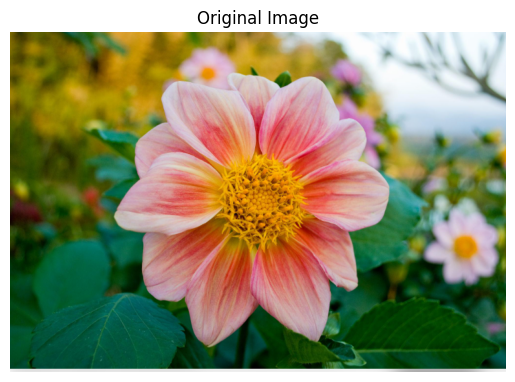

In [3]:
filename = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[filename], np.uint8),
    cv2.IMREAD_COLOR
)

if img is None:
    raise ValueError("Please upload a valid image.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [5]:
height, width = img.shape[:2]

x1 = width // 4
y1 = height // 4
x2 = 3 * width // 4
y2 = 3 * height // 4

roi = img[y1:y2, x1:x2].copy()

print("Region of Interest selected")
print("ROI dimensions:", roi.shape)

Region of Interest selected
ROI dimensions: (263, 384, 3)


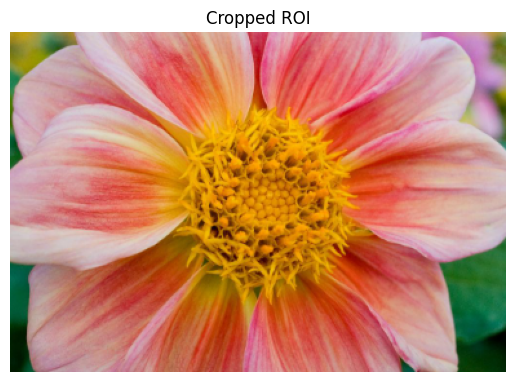

In [6]:
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

plt.imshow(roi_rgb)
plt.title("Cropped ROI")
plt.axis("off")
plt.show()

In [8]:
result = img.copy()

roi_height, roi_width = roi.shape[:2]

paste_x = 0
paste_y = 0

result[
    paste_y:paste_y + roi_height,
    paste_x:paste_x + roi_width
] = roi

print("ROI copied and pasted successfully")

ROI copied and pasted successfully


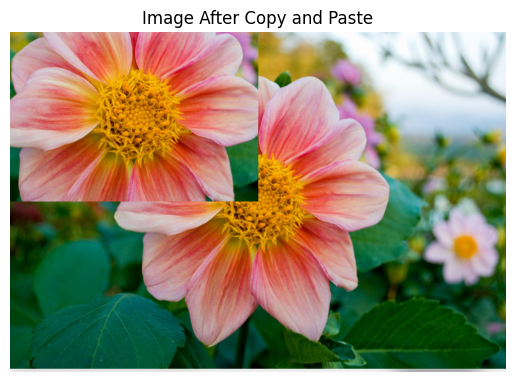

In [9]:
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.imshow(result_rgb)
plt.title("Image After Copy and Paste")
plt.axis("off")
plt.show()

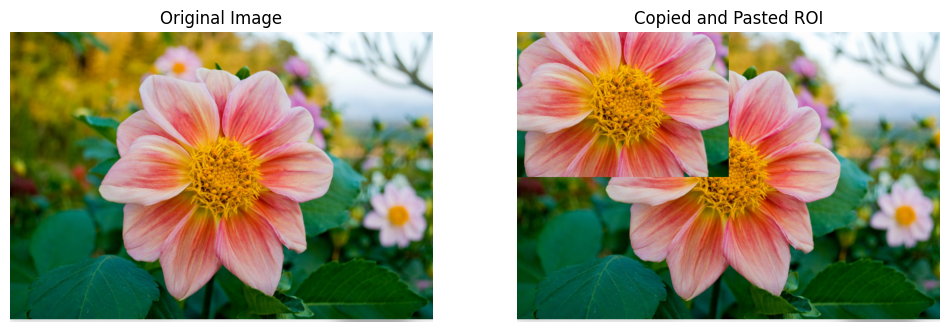

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title("Copied and Pasted ROI")
plt.axis("off")

plt.show()

In [11]:
cv2.imwrite("roi_image.jpg", result)
files.download("roi_image.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>